# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

brut = pd.read_csv("donnees/consommation_brut.csv")
display(brut.shape)
display(brut.dtypes)
display(brut.isna().sum())
brut.duplicated().sum()

(300, 4)

mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

np.int64(12)

**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [35]:
display(brut["quartier"].nunique())
brut["quartier"].value_counts().head(15)

43

quartier
Bois-Verna            24
Petite-Anse           24
Morne Calvaire        23
Delmas 33             22
Delmas 65             22
Carénage              22
Rue 15                22
Delmas 75             21
Centre-ville          20
Thomassin             20
Place Saint-Pierre    20
Bas-Peu-de-Chose      18
BOIS-VERNA             4
 Morne Calvaire        3
bas-peu-de-chose       2
Name: count, dtype: int64

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [36]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")
illisibles = brut.loc[converti.isna() & brut["kwh"].notna(), "kwh"]
display(len(illisibles))
illisibles.head(10)

52

0     184410 kWh
4     206280 kWh
9     215140 kWh
13       251 900
21    274520 kWh
27    301740 kWh
36    233010 kWh
43    155930 kWh
51    212510 kWh
53    424110 kWh
Name: kwh, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [37]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace("kWh", "", regex=False).str.replace(" ", "", regex=False)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
propre["kwh"].isna().sum()

np.int64(9)

**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [38]:
quartiers = pd.read_csv("donnees/quartiers.csv")
noms_officiels = {nom.lower(): nom for nom in quartiers["quartier"]}

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms_officiels)
display(propre["quartier"].isna().sum())  # noms perdus par map
propre["quartier"].nunique()

np.int64(0)

12

**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [39]:
avant = len(propre)
propre = propre.drop_duplicates()
apres_doublons = len(propre)
propre = propre.dropna(subset=["kwh"]).reset_index(drop=True)

pd.Series({
    "doublons supprimés": avant - apres_doublons,
    "lignes sans kwh supprimées": apres_doublons - len(propre),
    "lignes restantes": len(propre),
})

doublons supprimés             12
lignes sans kwh supprimées      9
lignes restantes              279
dtype: int64

**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [40]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grand = propre["kwh"] > 3 * mediane
display(propre[trop_grand])

propre.loc[trop_grand, "kwh"] = propre.loc[trop_grand, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)
propre["kwh"].max()

,mois,quartier,kwh,heures_courant
82,2025-02,Delmas 33,3602600.0,10.1
127,2025-02,Delmas 75,2012700.0,11.1
187,2024-02,Morne Calvaire,1439200.0,11.4
232,2024-01,Rue 15,997700.0,5.9


np.int64(742780)

**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [41]:
colonnes = ["mois", "quartier", "kwh", "heures_courant"]
reference = pd.read_csv("donnees/consommation.csv")[colonnes]

# La référence contient 288 lignes : on ne garde que les 279 relevés de `propre`
reference = reference.merge(propre[["mois", "quartier"]], on=["mois", "quartier"])
tri = ["quartier", "mois"]
a = propre[colonnes].sort_values(tri).reset_index(drop=True)
b = reference.sort_values(tri).reset_index(drop=True)

a.equals(b)

True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [42]:
avant = len(propre)
avec_quartiers = propre.merge(quartiers, on="quartier", how="left", validate="many_to_one")
display(pd.Series({"lignes avant": avant, "lignes après": len(avec_quartiers)}))

avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

avec_quartiers[(avec_quartiers["quartier"] == "Bas-Peu-de-Chose") & (avec_quartiers["mois"] == "2024-01")]

lignes avant    279
lignes après    279
dtype: int64

,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [43]:
meteo = pd.read_csv("donnees/meteo.csv")

avant = len(avec_quartiers)
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left", validate="many_to_one")
pd.Series({
    "lignes avant": avant,
    "lignes après": len(avec_meteo),
    "températures manquantes": avec_meteo["temperature_c"].isna().sum(),
})

lignes avant               279
lignes après               279
températures manquantes      0
dtype: int64

**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [44]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

relu = pd.read_csv("donnees/consommation_propre.csv")
display(relu.shape)
relu.head()

(279, 11)

,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64

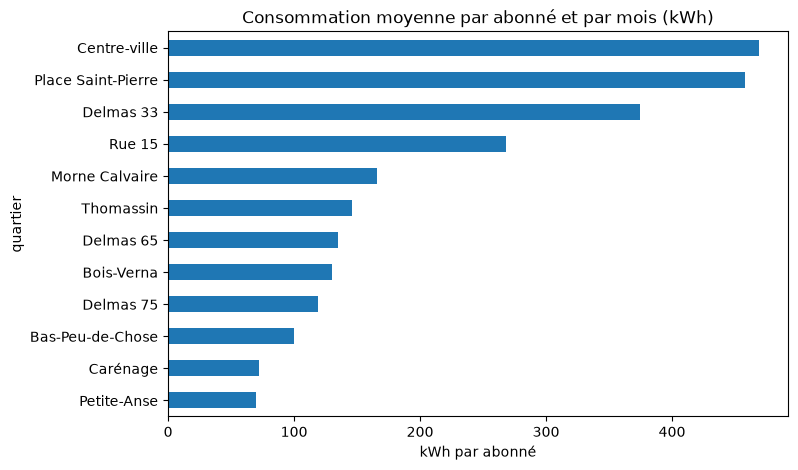

In [45]:
par_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
display(par_type)

classement = avec_meteo.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
display(classement)

classement.sort_values().plot(kind="barh", figsize=(8, 5), title="Consommation moyenne par abonné et par mois (kWh)")
plt.xlabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :** Un abonné d’un quartier commercial consomme en moyenne 393.2 kWh par mois, contre 117.4 pour un quartier résidentiel, soit environ 3.3 fois plus. Le haut du classement est entièrement commercial : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4), puis Rue 15 (268.5). Les derniers sont deux quartiers résidentiels de Cap-Haïtien, Petite-Anse (69.6) et Carénage (72.2).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee,2024,2025,hausse_pct
commune,,,
Cap-Haïtien,4.59,5.62,22.5
Pétion-Ville,8.60,9.68,12.6
Port-au-Prince,10.09,10.31,2.3
Delmas,11.61,11.74,1.1


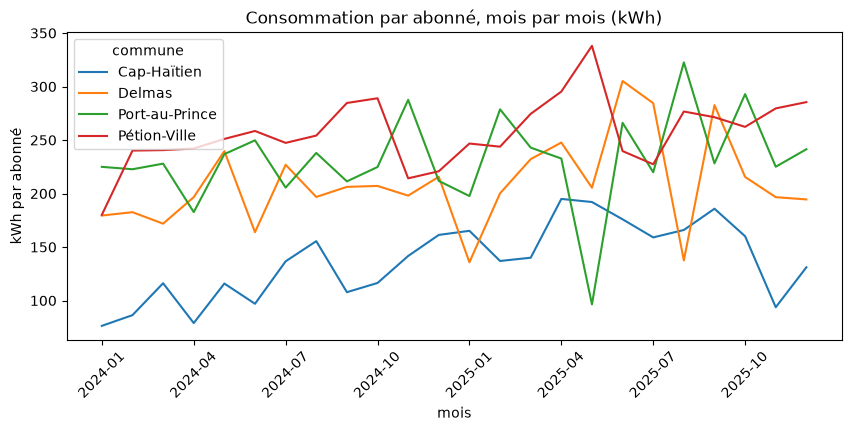

In [30]:
total = avec_meteo.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
total["hausse_pct"] = (total[2025] / total[2024] - 1) * 100

resume = (total[[2024, 2025]] / 1_000_000).round(2)
resume["hausse_pct"] = total["hausse_pct"].round(1)
display(resume.sort_values("hausse_pct", ascending=False))

courbes = avec_meteo.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()
courbes.plot(figsize=(10, 4), title="Consommation par abonné, mois par mois (kWh)")
plt.xticks(range(0, len(courbes), 3), courbes.index[::3], rotation=45)
plt.ylabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :** La consommation totale augmente dans les 4 communes entre 2024 et 2025, mais à des rythmes très différents : Cap-Haïtien passe de 4.59 à 5.62 millions de kWh (+22.5 %) et Pétion-Ville de 8.60 à 9.68 (+12.6 %), alors que Port-au-Prince (+2.3 %) et Delmas (+1.1 %) sont presque stables. Cap-Haïtien est pourtant la commune qui consomme le moins en volume : elle part de plus bas et rattrape son retard.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

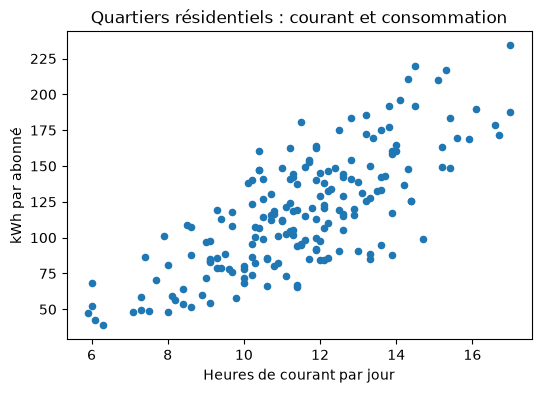

heures_courant    0.76
temperature_c    -0.15
dtype: float64

In [31]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

residentiel.plot(kind="scatter", x="heures_courant", y="kwh_par_abonne", figsize=(6, 4),
                 title="Quartiers résidentiels : courant et consommation")
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.show()

residentiel[["heures_courant", "temperature_c"]].corrwith(residentiel["kwh_par_abonne"]).round(2)

**Ce qu'on en conclut :** Dans les quartiers résidentiels, la consommation par abonné est fortement liée aux heures de courant (corrélation de 0.76) : plus il y a de courant, plus on consomme. Elle n’est presque pas liée à la température (-0.15), et le signe est même légèrement négatif : la chaleur ne ressort pas comme moteur de la consommation.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

,mediane,q1,q3
commune,,,
Cap-Haïtien,10.0,8.3,11.7
Delmas,11.9,10.1,13.0
Port-au-Prince,11.6,10.7,13.1
Pétion-Ville,11.6,10.4,13.0


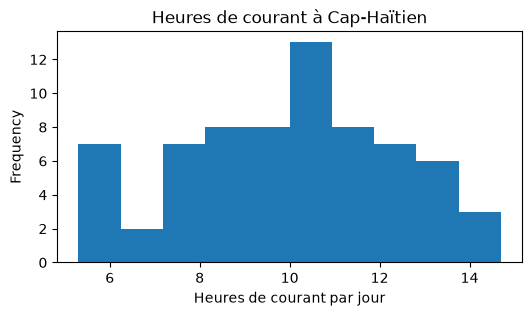

3

,mois,quartier,heures_courant
81,2025-01,Delmas 33,7.4
227,2025-08,Carénage,7.3
253,2025-11,Rue 15,5.9


In [32]:
heures = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
).round(1)
display(heures)

avec_meteo.loc[avec_meteo["commune"] == "Cap-Haïtien", "heures_courant"].plot(
    kind="hist", bins=10, figsize=(6, 3), title="Heures de courant à Cap-Haïtien")
plt.xlabel("Heures de courant par jour")
plt.show()

courts = avec_meteo[(avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)]
display(len(courts))
courts[["mois", "quartier", "heures_courant"]]

**Ce qu'on en conclut :** les coupures sont les plus longues à Cap-Haïtien, avec une médiane de 10.0 heures de courant par jour (Q1 à 8.3, Q3 à 11.7), contre 11.6 à 11.9 heures dans les autres communes. Seuls 3 relevés de 2025 passent sous 8 heures : Delmas 33 en janvier (7.4), Carénage en août (7.3) et Rue 15 en novembre (5.9), le plus bas.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [33]:
avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780
56,2024-11,Centre-ville,Commercial,597730
88,2025-09,Delmas 33,Commercial,591420


**Ce qu'on en conclut :** Les 3 plus grosses consommations sont toutes commerciales et viennent de deux quartiers : Delmas 33 en 2025-07 (742 780 kWh) et 2025-09 (591 420 kWh), Centre-ville en 2024-11 (597 730 kWh). Ce sont les plus gros relevés du fichier, et la règle « 3 fois la médiane » de la question 7 ne les a pas touchés : ils restent à vérifier auprès de la compagnie avant d’être interprétés.

## 9. Conclusion

La consommation suit surtout les heures de courant et non la chaleur : dans les quartiers résidentiels, la corrélation avec les heures de courant est de 0.76, contre -0.15 avec la température. Cela se voit à Cap-Haïtien, où les coupures sont les plus longues (médiane de 10.0 heures contre 11.6 à 11.9 ailleurs) et où la consommation par abonné est la plus basse (Petite-Anse 69.6 et Carénage 72.2 kWh), tandis que la commune a la plus forte hausse en 2025 (+22.5 %, de 4.59 à 5.62 millions de kWh). Une corrélation montre que deux séries varient ensemble, pas que l’une cause l’autre : les quartiers commerciaux consomment environ 3.3 fois plus (393.2 contre 117.4 kWh par abonné) et pourraient brouiller le lien, et deux ans de relevés ne suffisent pas à prouver que le courant est la cause.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.